In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
pd.set_option('display.max_columns', None)

## Load Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Path to dataset files: /kaggle/input/superstore-dataset-final


In [ ]:
df = pd.read_csv('/kaggle/input/superstore-dataset-final/Sample - Superstore.csv', encoding='latin1')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [ ]:
df.nunique()

,0
Row ID,9994
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,531


In [ ]:
data = df.groupby('Ship Mode')['Order ID'].count().reset_index()

## Plot to understand

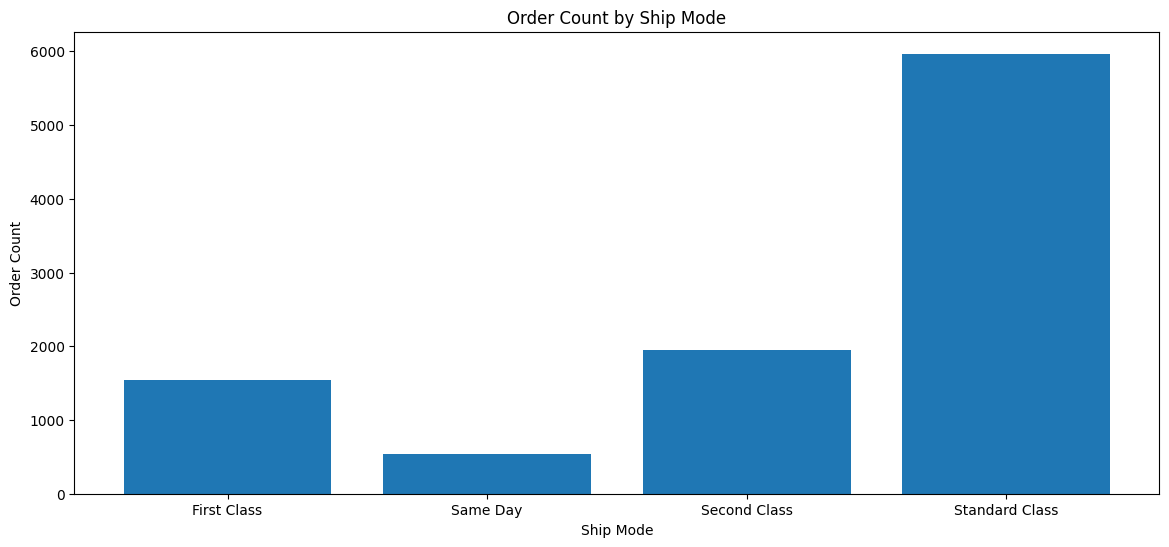

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
ax.bar(x='Ship Mode', height='Order ID', data=data)
ax.set_xlabel('Ship Mode')
ax.set_ylabel('Order Count')
ax.set_title('Order Count by Ship Mode')
plt.show()

## Consistency

In [ ]:
public_theme = {
    'font.family': 'sans-serif',
    'axes.titlesize': 'large'
}

In [ ]:
plt.rcParams.update(public_theme)

In [ ]:
sns.set_palette('Set2')

In [ ]:
df['Segment'].unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

In [ ]:
segment_color = {
    'Corporate': 'tab:red',
    'Home Office': 'tab:green',
    'Consumer': 'tab:blue'
}

In [ ]:
data = df.groupby('Segment')['Order ID'].count().reset_index()

In [ ]:
data

,Segment,Order ID
0,Consumer,5191
1,Corporate,3020
2,Home Office,1783


In [ ]:
color = data['Segment'].map(segment_color)

Text(0.5, 1.0, 'Order Count by Segment')

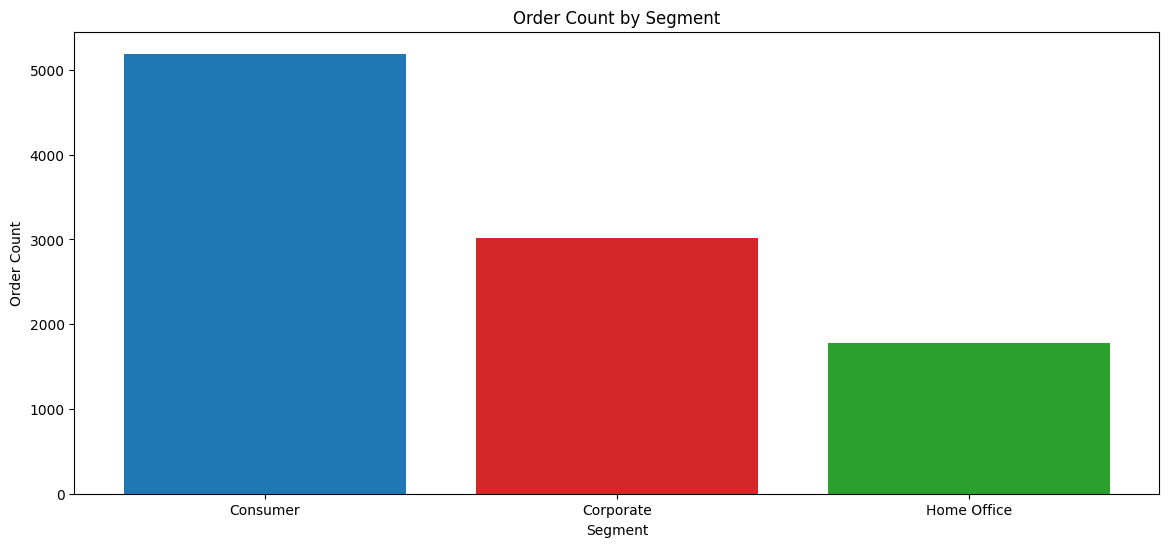

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
ax.bar(x = 'Segment', height='Order ID', data=data, color=color)
ax.set_xlabel('Segment')
ax.set_ylabel('Order Count')
ax.set_title('Order Count by Segment')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
data = df.groupby(['Segment', 'Order Date'])['Order ID'].count().reset_index()

In [ ]:
data.head()

,Segment,Order Date,Order ID
0,Consumer,2014-01-03,1
1,Consumer,2014-01-05,1
2,Consumer,2014-01-06,1
3,Consumer,2014-01-07,2
4,Consumer,2014-01-09,2


In [ ]:
data['Monthly'] = data['Order Date'].dt.to_period('M')
data['Monthly'] = data['Monthly'].dt.to_timestamp()

In [ ]:
data=data.groupby(['Segment', 'Monthly'])['Order ID'].count().reset_index()

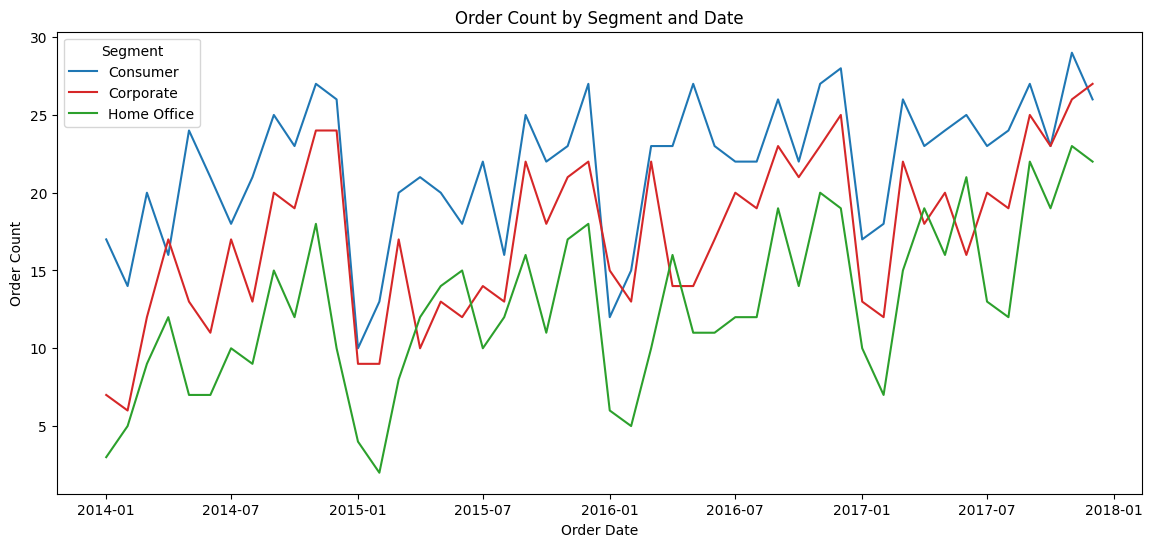

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
sns.lineplot(data=data, x='Monthly', y='Order ID', hue='Segment', palette=segment_color, ax = ax)
plt.xlabel('Order Date')
plt.ylabel('Order Count')
plt.title('Order Count by Segment and Date')
plt.show()

## Set Label, Legend, Grid Anotasi

In [ ]:
data = df.groupby('Segment')['Order ID'].count().reset_index()

[Text(0, 0, '5191'), Text(0, 0, '3020'), Text(0, 0, '1783')]

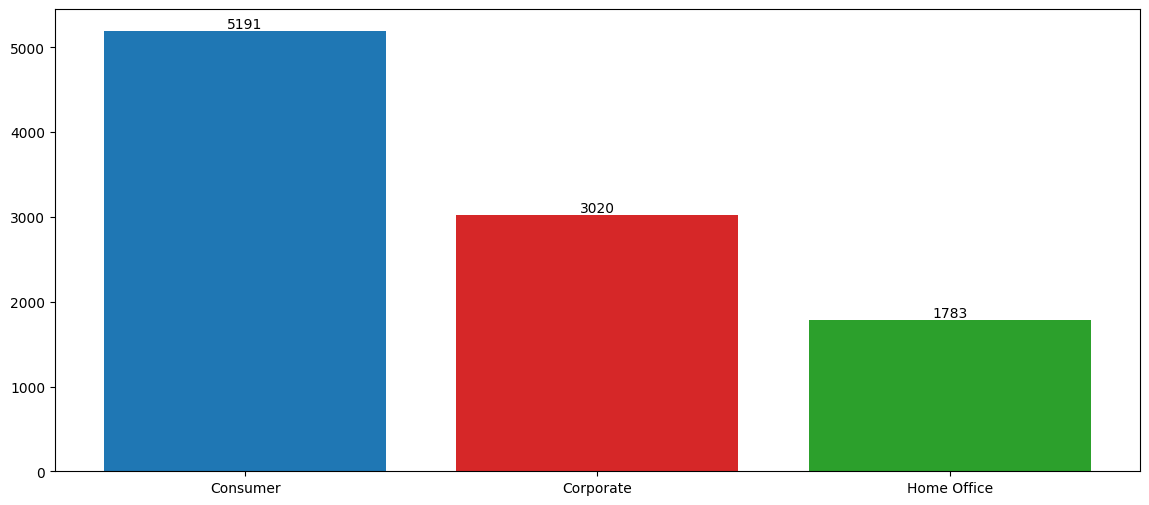

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
container = ax.bar(x = 'Segment', height='Order ID', data=data, color=color)
ax.bar_label(container)

In [ ]:
data.head()

,Segment,Order ID
0,Consumer,5191
1,Corporate,3020
2,Home Office,1783


In [ ]:
text = data[data['Segment'] == 'Consumer']['Order ID'].item()
x = data[data['Segment']== 'Consumer']['Segment'].item()
y = data[data['Segment']== 'Consumer']['Order ID'].item()

Text(250, -100, '5191')

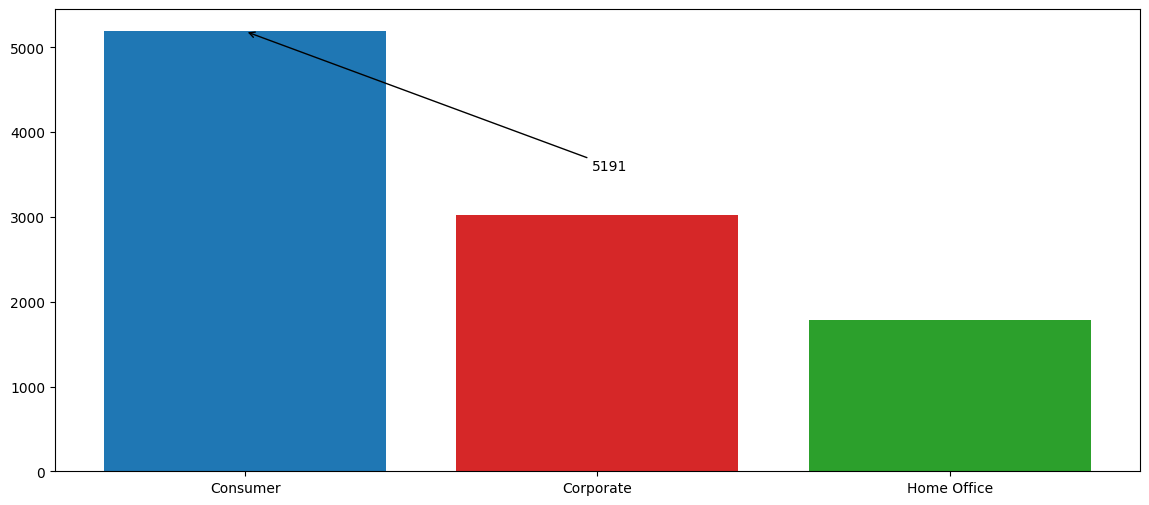

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
ax.bar(x = 'Segment', height='Order ID', data=data, color=color)
ax.annotate(
    text=text,
    xy = (x,y),
    arrowprops=dict(
        arrowstyle='->'
    ),
    xytext=(250,-100),
    textcoords='offset points'
)

In [ ]:
data = df.groupby(['Segment', 'Order Date'])['Order ID'].count().reset_index()

In [ ]:
data['Monthly'] = data['Order Date'].dt.to_period('M')
data['Monthly'] = data['Monthly'].dt.to_timestamp()
data=data.groupby(['Segment', 'Monthly'])['Order ID'].count().reset_index()

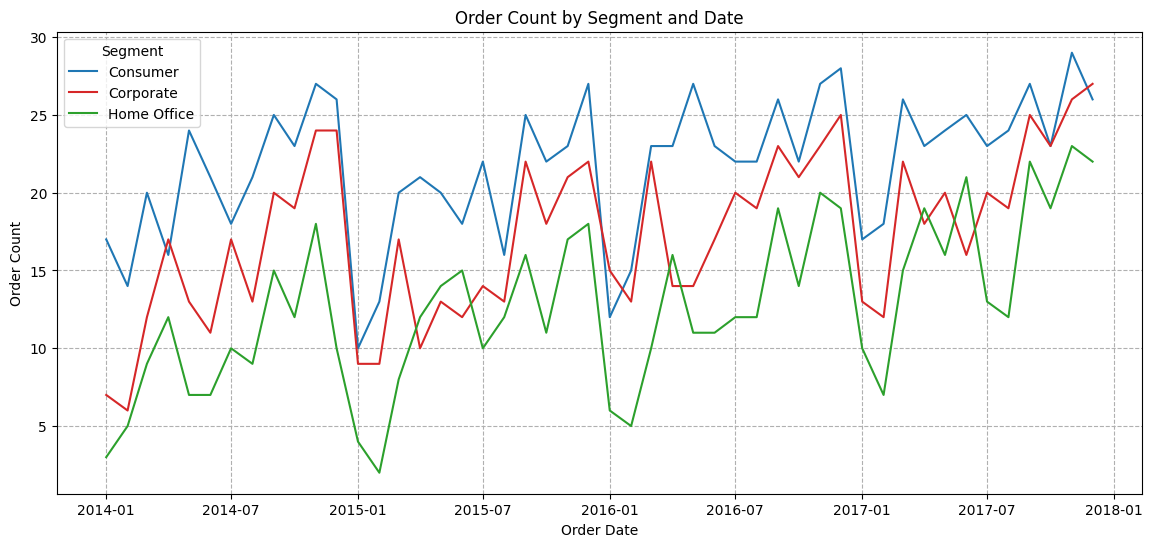

In [ ]:
from matplotlib.lines import lineStyles
fig, ax = plt.subplots(figsize=(14,6))
sns.lineplot(data=data, x='Monthly', y='Order ID', hue='Segment', palette=segment_color, ax = ax)
plt.xlabel('Order Date')
plt.ylabel('Order Count')
plt.title('Order Count by Segment and Date')
plt.grid(linestyle='--')
plt.show()

## Fills
- `plt.fill_between`
- `plt.fill_betweenx`
- `plt.axvspan`
- `plt.axhspan`

documentation : https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.fill_between.html

In [ ]:
df['Monthly'] = df['Order Date'].dt.to_period('M')
df['Monthly'] = df['Monthly'].dt.to_timestamp()
data=df.groupby('Monthly')['Order ID'].count().reset_index()

Text(0.5, 1.0, 'Order Count by Segment and Date')

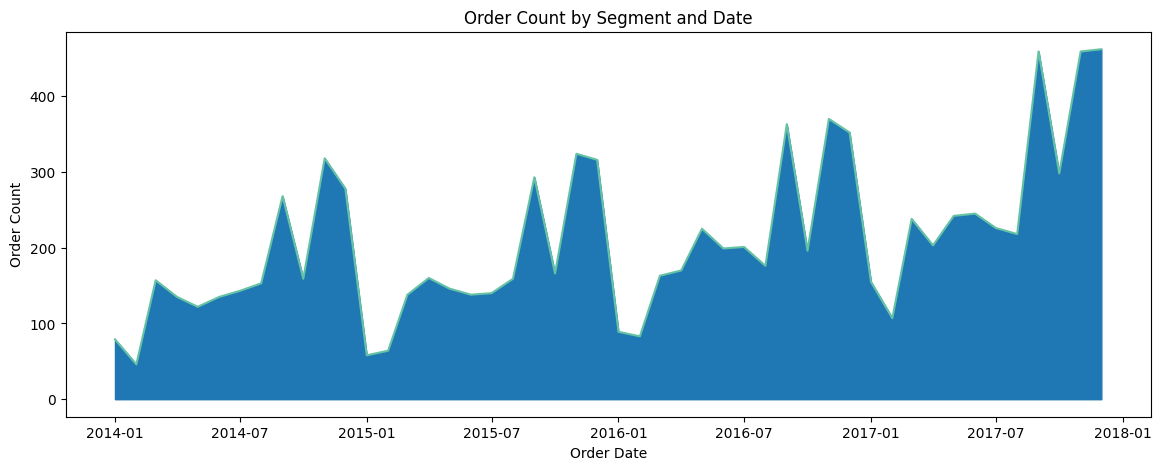

In [ ]:
fig, ax = plt.subplots(figsize=(14,5))
sns.lineplot(data=data, x='Monthly', y='Order ID', ax = ax)
ax.fill_between(x=data['Monthly'], y1=data['Order ID'], color='tab:blue')
plt.xlabel('Order Date')
plt.ylabel('Order Count')
plt.title('Order Count by Segment and Date')

Text(0.5, 1.0, 'Order Count by Segment and Date')

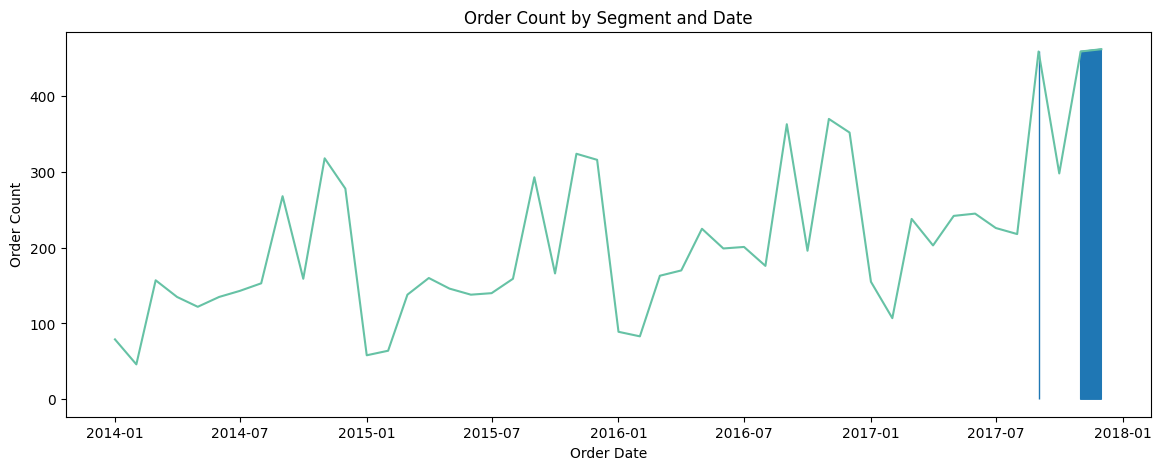

In [ ]:
fig, ax = plt.subplots(figsize=(14,5))
sns.lineplot(data=data, x='Monthly', y='Order ID', ax = ax)
x = data['Monthly']
y = data['Order ID']
ax.fill_between(x=x, y1=y, where=(y > 400), color='tab:blue')
plt.xlabel('Order Date')
plt.ylabel('Order Count')
plt.title('Order Count by Segment and Date')

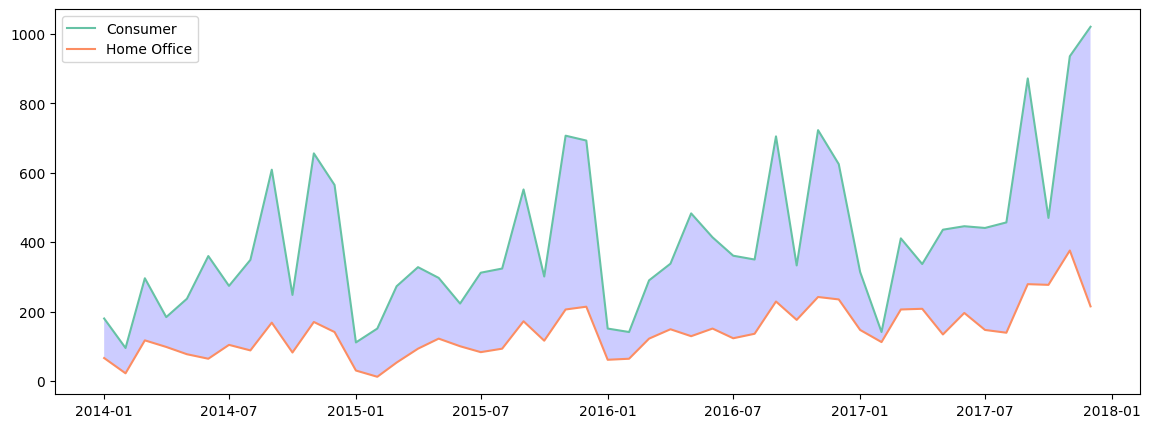

In [ ]:
fig, ax = plt.subplots(figsize = (14,5))
df['Monthly'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()
data = df.groupby(['Monthly', 'Segment'])['Quantity'].sum().reset_index()
data = data.pivot(index='Monthly', columns='Segment', values='Quantity').reset_index()
data = data.rename_axis(None, axis=1)
x = data['Monthly']
y1 = data['Consumer']
y2 = data['Home Office']
ax.plot(x, y1, label='Consumer')
ax.plot(x, y2, label='Home Office')
plt.fill_between(x, y1, y2, facecolor='blue', alpha=0.2)
plt.legend()
plt.show()

## Discrete & Continuous Color

### Discrete Color

In [ ]:
sns.set_palette('Set2')

In [ ]:
data = df.groupby('Region')['Quantity'].sum().reset_index()

<Axes: xlabel='Region', ylabel='Quantity'>

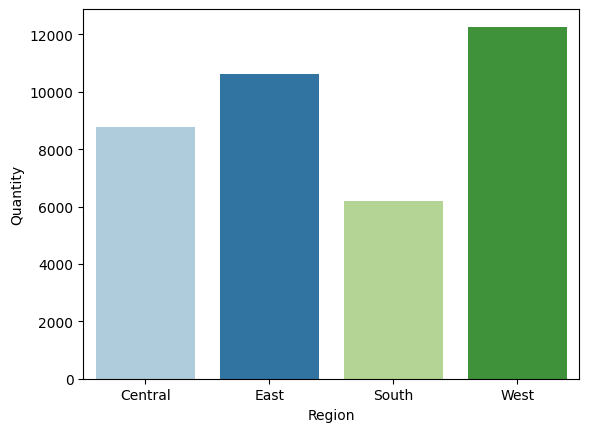

In [ ]:
sns.barplot(data=data, x='Region', y='Quantity', hue = 'Region', palette='Paired')

### Continuous Color

In [ ]:
num_col = ['Profit', 'Discount', 'Quantity', 'Sales']
data = df[num_col]

In [ ]:
data.head()

,Profit,Discount,Quantity,Sales
0,41.9136,0.00,2,261.9600
1,219.5820,0.00,3,731.9400
2,6.8714,0.00,2,14.6200
3,-383.0310,0.45,5,957.5775
4,2.5164,0.20,2,22.3680


In [ ]:
corr = data.corr()

<Axes: >

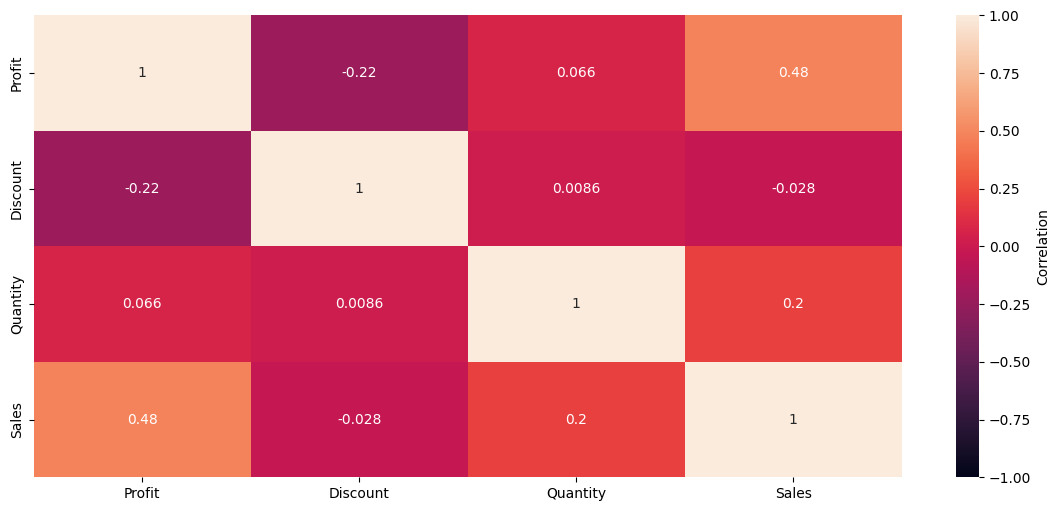

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))

sns.heatmap(
    data=corr,
    annot=True,
    # cmap='viridis',
    vmin=-1,
    vmax=1,
    annot_kws={'fontsize':10},
    cbar_kws={'label' : 'Correlation'},
    ax=ax
)

## Facet Plot

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Monthly
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016-11-01
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016-11-01
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016-06-01
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015-10-01
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015-10-01


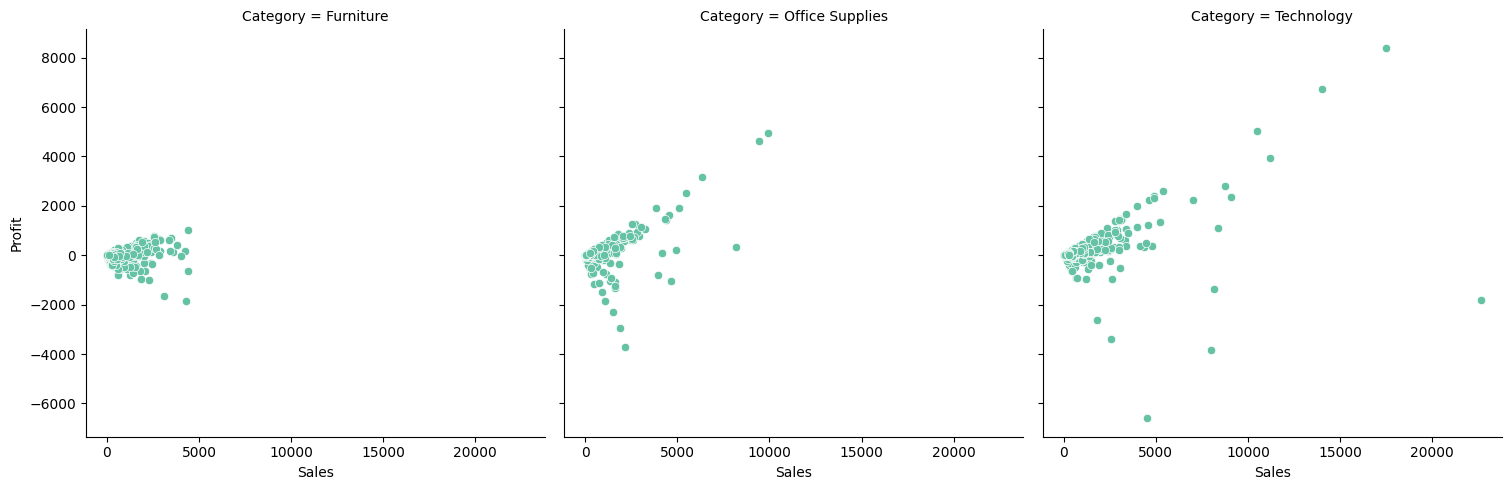

In [ ]:
sns.relplot(
    data=df,
    x = 'Sales',
    y = 'Profit',
    col = 'Category',
    col_wrap=4,
    kind='scatter'
)

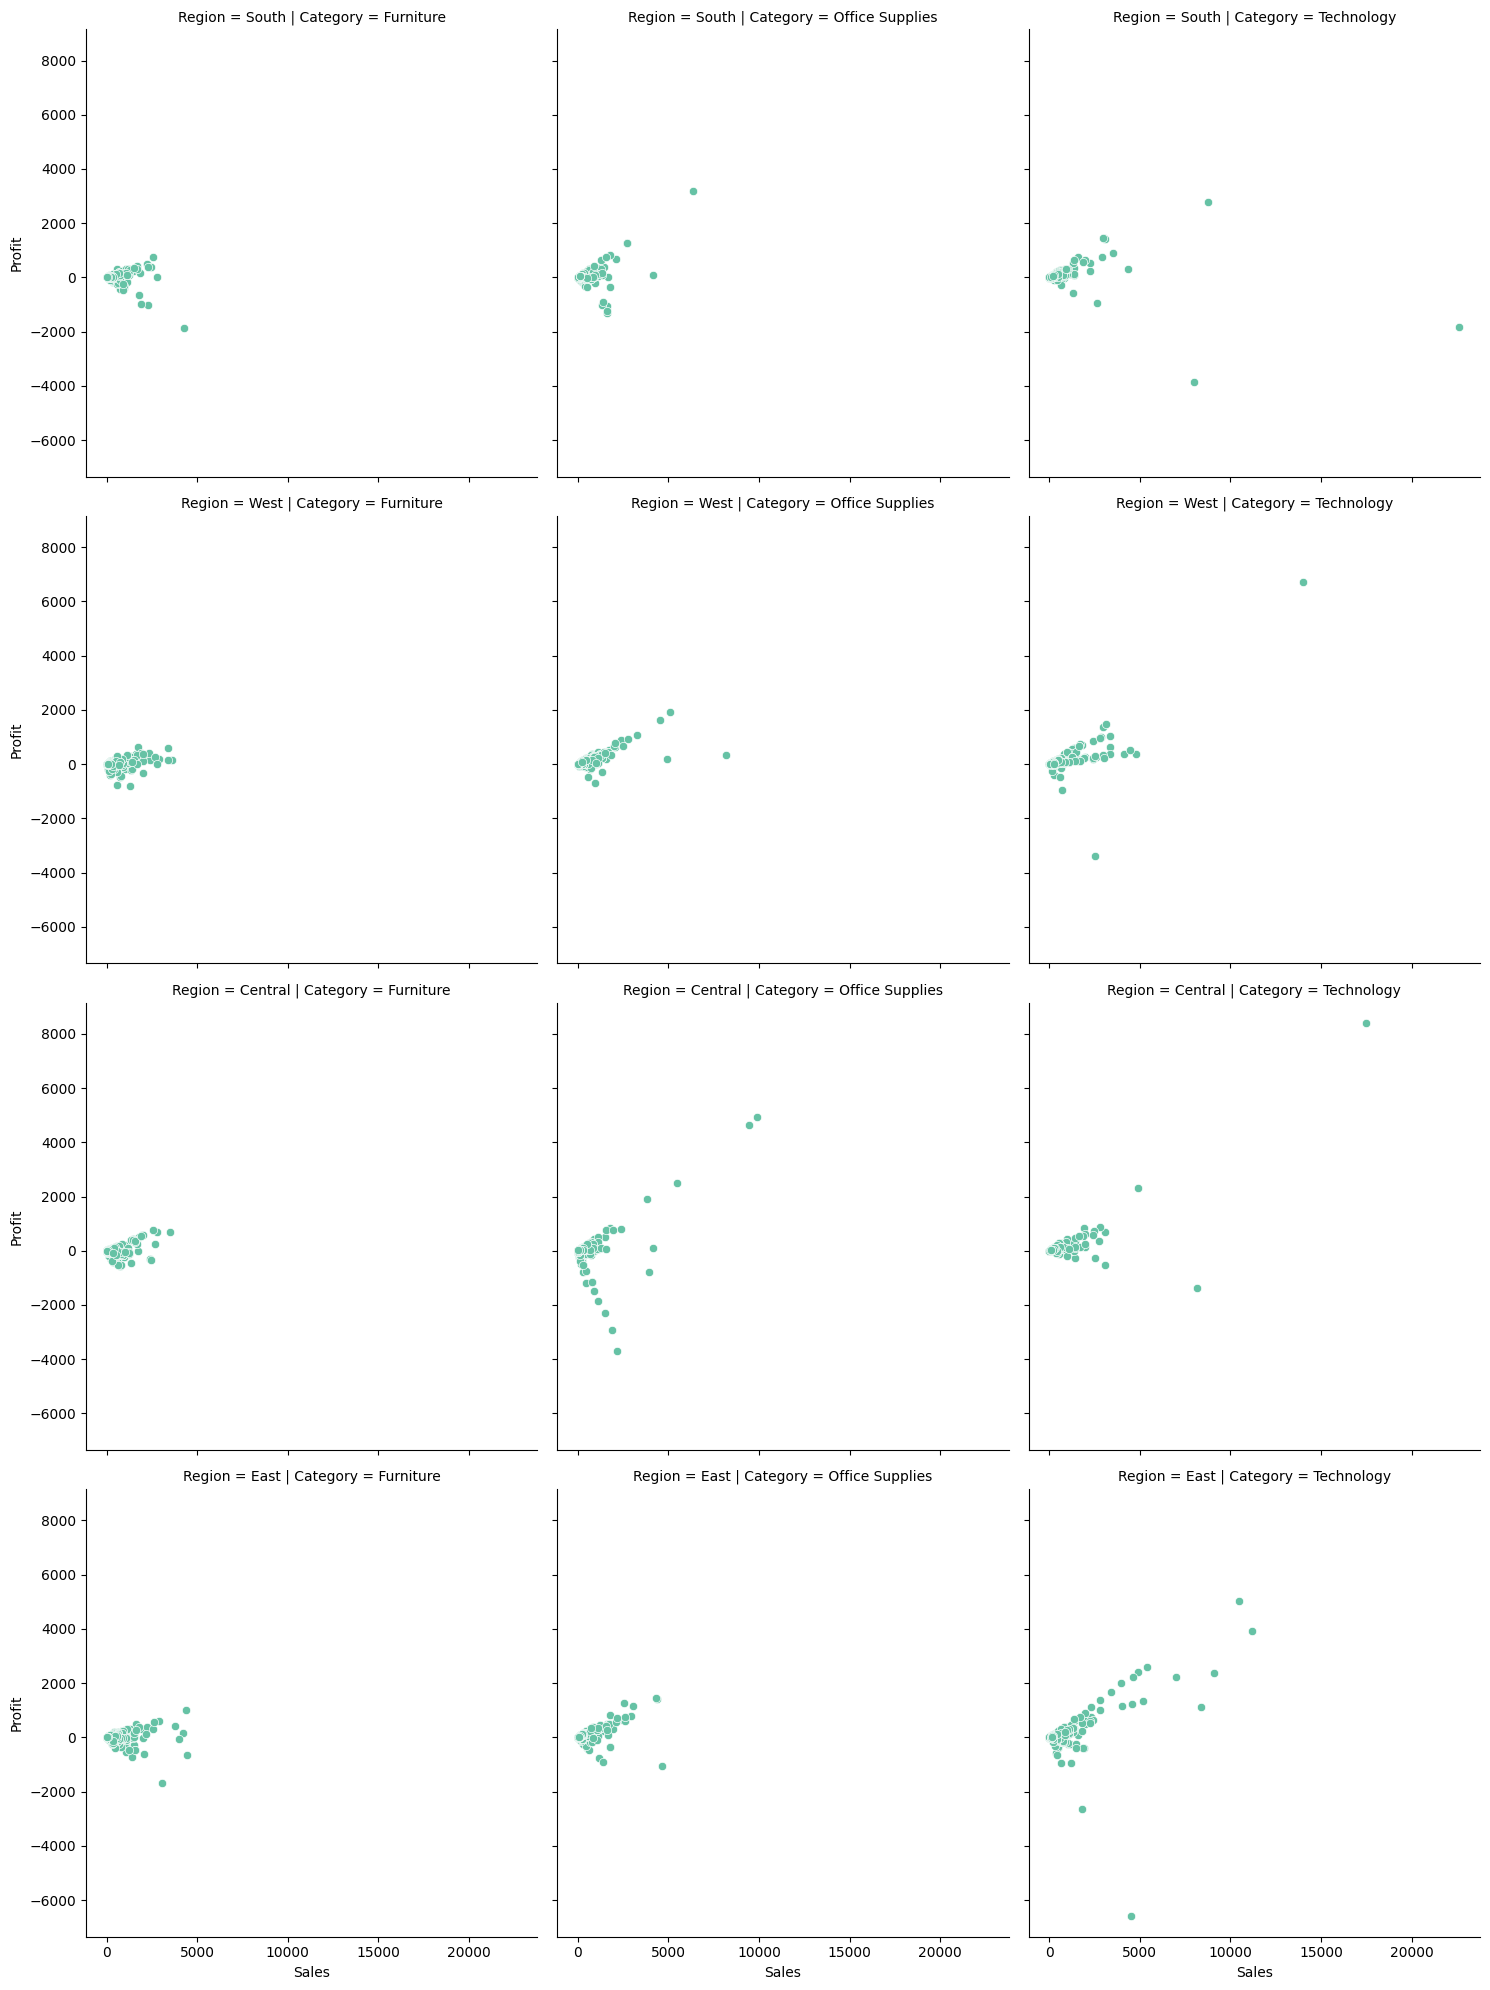

In [ ]:
sns.relplot(
    data=df,
    x = 'Sales',
    y = 'Profit',
    col = 'Category',
    row = 'Region',
    kind='scatter'
)